# IoT Traffic Pipeline — Data Preparation and EDA

This notebook creates reproducible metadata-only derivatives of the packet captures. It never writes to the original dataset and never extracts packet payloads. The main goals are to align timestamps, map hub traffic to logical child devices, quantify label quality, and create one-second aggregates for causal modeling.

In [1]:
from pathlib import Path
import subprocess, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT))

from src.iot_pipeline import *

DATASET = Path("/Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job/dataset/IoT-Dataset")
DERIVED = PROJECT / "derived"
PACKET_DIR = DERIVED / "packet_csv"
SECOND_DIR = DERIVED / "secondly"
PREPARED_DIR = DERIVED / "prepared"
FIGURE_DIR = PROJECT / "artifacts" / "figures"
for path in (PACKET_DIR, SECOND_DIR, PREPARED_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

assert DATASET.exists() and TSHARK.exists()
dataset_git_before = subprocess.run(
    ["git", "-C", str(DATASET), "status", "--porcelain"], capture_output=True, text=True, check=True
).stdout
print("Python:", sys.version.split()[0])
print("Dataset pre-existing git changes:", repr(dataset_git_before))

Python: 3.12.13
Dataset pre-existing git changes: '?? scripts/CompanionSync/NotificationSync/.gradle/\n'


/Users/duongtuanhoang/anaconda3/envs/phase34/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Capture manifest and label ontology

A PCAP represents a network endpoint, but a label may describe a child device behind that endpoint. Exact captures take precedence; otherwise the dataset's hub map is used. Two missing registry entries are filled from packet-header inspection, including `hub-02`, whose MAC matches `august-hub-02`.

In [2]:
manifest = capture_manifest(DATASET)
raw_labels, labels = canonicalize_labels(DATASET, manifest)

label_quality = pd.Series({
    "raw labels": len(raw_labels),
    "mapped to available capture": int(raw_labels.has_capture.sum()),
    "missing capture": int((~raw_labels.has_capture).sum()),
    "invalid/nonexistent DST time": int((~raw_labels.dst_valid).sum()),
    "usable canonical labels": len(labels),
    "primary semantic labels": len(precise_semantic_labels(labels)),
    "weak minute labels": int(labels.is_weak_label.sum()),
    "telemetry/background labels": int(labels.is_telemetry.sum()),
}).rename("count")
display(label_quality.to_frame())

missing = raw_labels.loc[~raw_labels.has_capture, "source_device_id"].value_counts().rename("labels")
display(missing.to_frame())
display(manifest[["capture_id", "description", "local_ip", "pcap_size_bytes"]].head())

,count
raw labels,17454
mapped to available capture,15254
missing capture,2200
invalid/nonexistent DST time,28
usable canonical labels,14936
primary semantic labels,12408
weak minute labels,543
telemetry/background labels,1985


,labels
source_device_id,
kasa-cam-01,1548
ring-doorbell-01,341
nest-cam-01,194
ring-light-01,117


,capture_id,description,local_ip,pcap_size_bytes
0,arlo-hub-01,Arlo Base Station,192.168.1.100,70495739
1,august-hub-01,August Connect Wi-Fi Bridge,192.168.1.123,22520284
2,blink-cam-01,Blink Indoor Home Security Camera 1,192.168.1.129,1787403
3,blink-cam-02,Blink Indoor Home Security Camera 2,192.168.1.130,1721332
4,blink-cam-03,Blink Indoor Home Security Camera 3,192.168.1.126,1913994


## Packet metadata extraction

Each PCAP is streamed through `tshark` into a separate gzip CSV under `derived/packet_csv/`. Only timing, size, direction, protocol, port, flag, DNS, and TLS metadata are retained. The extractor is restartable and validates the gzip header before reusing a cached file.

In [3]:
packet_paths = export_all_pcaps(manifest, PACKET_DIR)
assert len(packet_paths) == len(manifest)
assert all(p.read_bytes()[:2] == b"\x1f\x8b" for p in packet_paths)
print(f"Exported or validated {len(packet_paths)} compressed packet CSV files.")

PCAP → CSV.gz:   0%|          | 0/32 [00:00<?, ?it/s]

PCAP → CSV.gz: 100%|██████████| 32/32 [00:00<00:00, 3298.62it/s]

Exported or validated 32 compressed packet CSV files.


## One-second aggregates

Packet rows are reduced to sufficient statistics at one-second resolution. This makes the later 5–30 second causal window search practical while retaining direction, packet-size, inter-arrival, protocol, and burst information.

In [4]:
manifest = aggregate_all_packet_csvs(manifest, PACKET_DIR, SECOND_DIR)
manifest.to_csv(PREPARED_DIR / "capture_manifest.csv", index=False)
raw_labels.to_parquet(PREPARED_DIR / "raw_labels_audit.parquet", index=False)
labels.to_parquet(PREPARED_DIR / "canonical_labels.parquet", index=False)

display(manifest[["capture_id", "packet_count", "active_seconds", "start_epoch", "end_epoch"]].describe())
print("Total packets represented:", f"{manifest.packet_count.sum():,.0f}")

CSV.gz → 1-second features:   0%|          | 0/32 [00:00<?, ?it/s]

CSV.gz → 1-second features:   3%|▎         | 1/32 [00:00<00:03,  8.87it/s]

CSV.gz → 1-second features:  41%|████      | 13/32 [00:00<00:00, 68.14it/s]

CSV.gz → 1-second features:  91%|█████████ | 29/32 [00:00<00:00, 107.20it/s]

CSV.gz → 1-second features: 100%|██████████| 32/32 [00:00<00:00, 93.92it/s] 

,packet_count,active_seconds,start_epoch,end_epoch
count,3.200000e+01,32.000000,3.200000e+01,3.200000e+01
mean,6.874084e+05,128212.937500,1.615214e+09,1.615827e+09
std,1.028140e+06,145828.629753,1.219858e+03,5.568430e+04
min,1.115000e+04,383.000000,1.615211e+09,1.615588e+09
25%,1.586372e+05,23634.250000,1.615214e+09,1.615843e+09
50%,2.955860e+05,80553.000000,1.615214e+09,1.615843e+09
75%,6.304230e+05,166142.000000,1.615214e+09,1.615843e+09
max,4.045374e+06,616238.000000,1.615217e+09,1.615843e+09


Total packets represented: 21,997,069


## Label and traffic EDA

Telemetry is intentionally retained as background rather than silently discarded. Start/end variants are normalized to semantic event families, while state changes such as open/close and lock/unlock remain distinct.

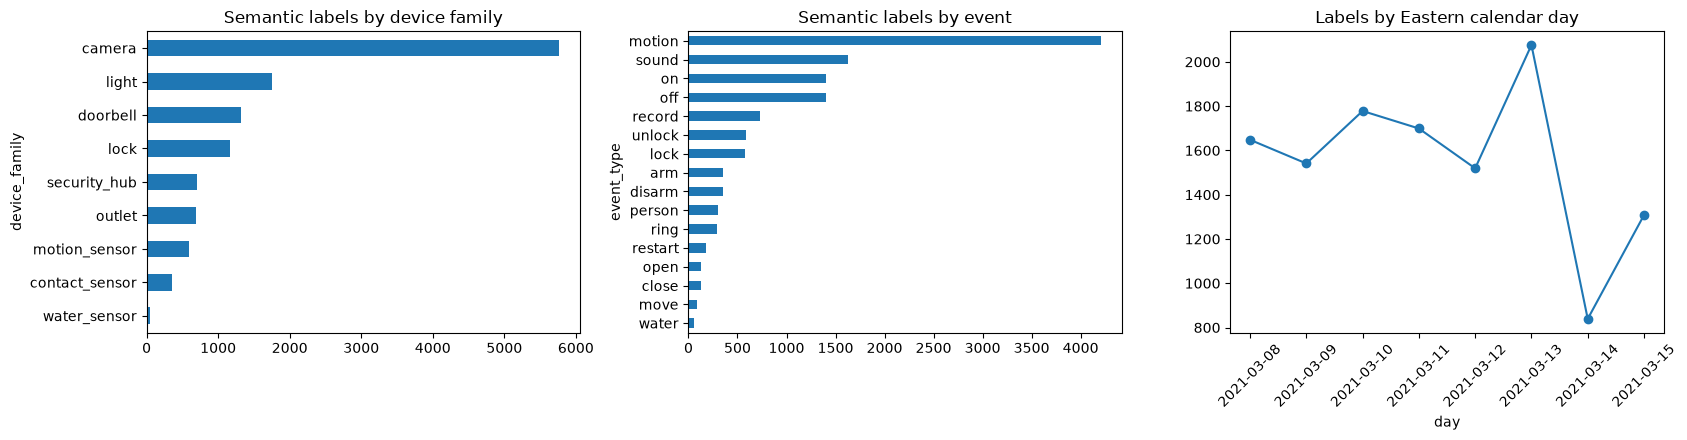

Timestamps with multiple logical families: 14
Timestamps with multiple event labels: 958


families  events  labels
capture_id         timestamp_utc                                      
ring-hub-01        2021-03-08 15:10:47+00:00         2       2       2
smartthings-hub-01 2021-03-10 19:45:00+00:00         2       2       2
                   2021-03-11 19:29:08+00:00         2       2       2
                   2021-03-13 18:58:45+00:00         2       2       2
                   2021-03-13 19:01:28+00:00         2       2       2
                   2021-03-13 19:02:01+00:00         2       2       2
                   2021-03-13 19:05:34+00:00         2       2       2
                   2021-03-13 19:07:34+00:00         2       2       2
                   2021-03-13 19:14:17+00:00         2       2       2
                   2021-03-13 19:14:18+00:00         2       2       2

In [5]:
semantic = precise_semantic_labels(labels)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
semantic.device_family.value_counts().sort_values().plot.barh(ax=axes[0], title="Semantic labels by device family")
semantic.event_type.value_counts().sort_values().plot.barh(ax=axes[1], title="Semantic labels by event")
semantic.assign(day=semantic.timestamp_utc.dt.tz_convert(LABEL_TZ).dt.date).groupby("day").size().plot(
    ax=axes[2], marker="o", title="Labels by Eastern calendar day"
)
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

simultaneous = semantic.groupby(["capture_id", "timestamp_utc"]).agg(
    families=("device_family", "nunique"), events=("event_type", "nunique"), labels=("event_type", "size")
)
print("Timestamps with multiple logical families:", int((simultaneous.families > 1).sum()))
print("Timestamps with multiple event labels:", int((simultaneous.labels > 1).sum()))
display(simultaneous.sort_values(["families", "labels"], ascending=False).head(10))

## Event-aligned activity and window justification

Labels are Eastern wall-clock times. Packet timestamps are absolute epochs, even though Wireshark displays them in the workstation's local timezone. Converting both to UTC reveals event-associated bursts that disappear under the erroneous one-hour shift. The plot summarizes packet activity around precise semantic labels on a sample of captures.

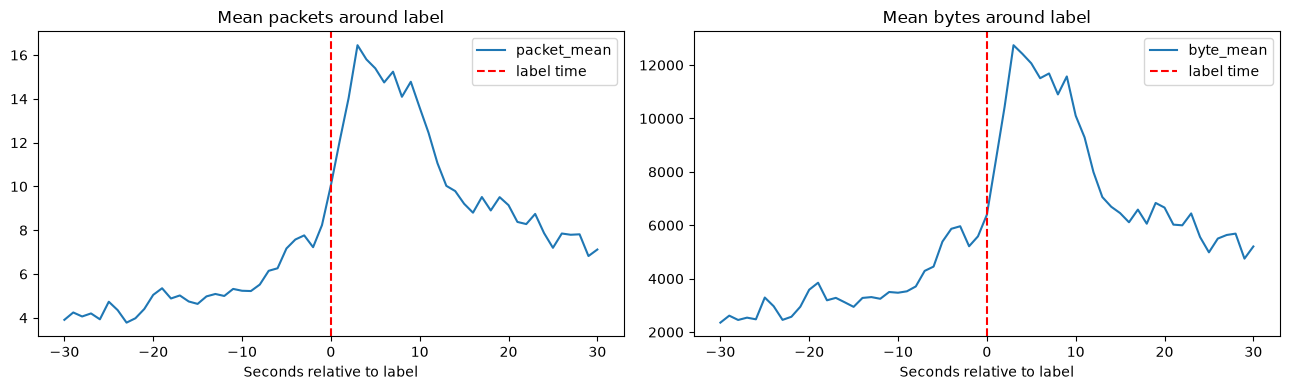

Mean bytes/s: pre-event=3582.3, first 10s=10749.4, first 30s=7864.1


In [6]:
profiles = []
sampled = semantic.sample(min(2500, len(semantic)), random_state=SEED)
for capture_id, group in sampled.groupby("capture_id"):
    path = SECOND_DIR / f"{capture_id}.parquet"
    if not path.exists():
        continue
    sec = pd.read_parquet(path, columns=["second_epoch", "packet_count", "byte_sum"]).set_index("second_epoch")
    lookup_packets = sec.packet_count.to_dict()
    lookup_bytes = sec.byte_sum.to_dict()
    for timestamp in group.timestamp_utc:
        center = int(timestamp.timestamp())
        for offset in range(-30, 31):
            profiles.append((offset, lookup_packets.get(center + offset, 0), lookup_bytes.get(center + offset, 0)))
profile = pd.DataFrame(profiles, columns=["offset", "packets", "bytes"])
aligned = profile.groupby("offset").agg(packet_mean=("packets", "mean"), byte_mean=("bytes", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
aligned.packet_mean.plot(ax=axes[0], title="Mean packets around label")
aligned.byte_mean.plot(ax=axes[1], title="Mean bytes around label")
for ax in axes:
    ax.axvline(0, color="red", linestyle="--", label="label time")
    ax.set_xlabel("Seconds relative to label")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "event_aligned_activity.png", dpi=150, bbox_inches="tight")
plt.show()

pre = aligned.loc[-30:-1, "byte_mean"].mean()
post10 = aligned.loc[0:10, "byte_mean"].mean()
post30 = aligned.loc[0:30, "byte_mean"].mean()
print(f"Mean bytes/s: pre-event={pre:.1f}, first 10s={post10:.1f}, first 30s={post30:.1f}")

### Preparation findings

The largest surprise was not a model result but a data-integrity issue: interpreting label strings in Chicago time creates a silent one-hour error. Correct Eastern-to-UTC conversion exposes bursts immediately after representative labels. Hub traces also contain simultaneous logical-device labels, confirming that Phase 2 and Phase 3 must be multi-label. Finally, background is device-dependent—some cameras produce steady high-volume traffic—so raw byte volume alone cannot be the event detector.

The training notebook will compare 5, 10, 20, and 30-second causal windows at a two-second stride and select the shortest window meeting the validation rule. Thirty seconds is a hard cap, not a requirement to wait 30 seconds after every event; in a running system the buffer is continuously maintained.

In [7]:
dataset_git_after = subprocess.run(
    ["git", "-C", str(DATASET), "status", "--porcelain"], capture_output=True, text=True, check=True
).stdout
assert dataset_git_after == dataset_git_before, "The source dataset changed during preparation."
assert len(list(PACKET_DIR.glob("*.csv.gz"))) == len(manifest)
assert len(list(SECOND_DIR.glob("*.parquet"))) == len(manifest)
print("Verification passed: source dataset unchanged and all derived captures are present.")

Verification passed: source dataset unchanged and all derived captures are present.
